In [1]:
# import
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import MNIST, SVHN
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import os, time

In [2]:
transform_mnist = transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
transform_svhn = transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

In [3]:
mnist_train = MNIST(root='./data', train=True, download=False, transform=transform_mnist)
svhn_train  = SVHN(root='./data', split='train', download=False, transform=transform_svhn)

In [4]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize to pot
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

In [5]:
class PairedMNISTSVHN(Dataset):
    def __init__(self, mnist_dataset, svhn_dataset):
        self.mnist = mnist_dataset
        self.svhn = svhn_dataset

        mnist_targets = np.array(self.mnist.targets)
        svhn_labels = np.array(self.svhn.labels)
        # SVHN usa la etiqueta 10 para representar el dígito 0 (quirk histórico del dataset)
        svhn_labels = np.where(svhn_labels == 10, 0, svhn_labels)
        self.svhn_labels = svhn_labels

        # índices de cada dataset agrupados por dígito (0-9)
        self.mnist_by_label = {d: np.where(mnist_targets == d)[0] for d in range(10)}
        self.svhn_by_label  = {d: np.where(svhn_labels == d)[0] for d in range(10)}

        # longitud "artificial" del dataset emparejado
        self.length = max(len(self.mnist), len(self.svhn))

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        digit = np.random.randint(0, 10)
        m_idx = np.random.choice(self.mnist_by_label[digit])
        s_idx = np.random.choice(self.svhn_by_label[digit])

        x_mnist, _ = self.mnist[m_idx]
        x_svhn, _  = self.svhn[s_idx]

        return x_mnist, x_svhn, digit

In [6]:
paired_dataset = PairedMNISTSVHN(mnist_train, svhn_train)
paired_loader = DataLoader(paired_dataset, batch_size=64, shuffle=True)

C:\Users\sampe\AppData\Local\Temp\ipykernel_10244\3222552724.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  mnist_targets = np.array(self.mnist.targets)


In [7]:
import torch
import torch.nn as nn

class encoder_s(nn.Module):
    def __init__(self, dimz_shared, dimz_private, channels=3, var_x=0.1):
        super().__init__()
        
        self.dimz_shared = dimz_shared    # Dimensión del contenido (z1)
        self.dimz_private = dimz_private  # Dimensión del estilo (w_s)

        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=32, kernel_size=4, stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32, kernel_size=4, stride=2, padding=1)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2, padding=1)
        self.conv4 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=4, stride=2, padding=1)
        self.conv5 = nn.Conv2d(in_channels=64, out_channels=256, kernel_size=4, stride=1, padding=0)

        self.relu = nn.ReLU()
        self.softplus = nn.Softplus()

        # Proyectamos a (media + varianza) para SHARED y (media + varianza) para PRIVATE
        total_dimz = (dimz_shared + dimz_private) * 2
        self.linear = nn.Linear(256, total_dimz)

    def forward(self, x):
        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z))
        z = self.relu(self.conv3(z))
        z = self.relu(self.conv4(z))
        z = self.relu(self.conv5(z))
        z = z.view(-1, 256)
        z = self.linear(z)
        return z

    def encode_and_sample(self, x, flag_sample=True):
        z = self.forward(x)

        # 1. Separar salidas para espacio COMPARTIDO (z1)
        mu_shared = z[:, :self.dimz_shared]
        var_shared = self.softplus(0.5 * z[:, self.dimz_shared : 2 * self.dimz_shared])

        # 2. Separar salidas para espacio PRIVADO (w_s)
        idx_priv = 2 * self.dimz_shared
        mu_private = z[:, idx_priv : idx_priv + self.dimz_private]
        var_private = self.softplus(0.5 * z[:, idx_priv + self.dimz_private :])

        # Reparametrización
        sample_shared, sample_private = None, None
        if flag_sample:
            eps_s = torch.randn_like(var_shared)
            sample_shared = mu_shared + eps_s * (var_shared ** 0.5)

            eps_p = torch.randn_like(var_private)
            sample_private = mu_private + eps_p * (var_private ** 0.5)

        # Devolvemos tuplas con (mu, var, sample) para cada subespacio
        return (mu_shared, var_shared, sample_shared), (mu_private, var_private, sample_private)

In [8]:
class decoder_s(nn.Module):
    def __init__(self, dimz_shared, dimz_private, channels=3, var_x=0.1):
        super().__init__()

        # El decoder recibe la concatenación del vector de contenido y de estilo
        in_dimz = dimz_shared + dimz_private
        self.linear = nn.Linear(in_dimz, 256)

        self.relu = nn.ReLU()
        self.tanh = nn.Tanh()

        self.tconv1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=1, padding=0)
        self.tconv2 = nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1)
        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1)
        self.tconv4 = nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2, padding=1)
        self.tconv5 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2, padding=1)

    def forward(self, z):
        # 'z' ya debe venir concatenado desde fuera: torch.cat([z1, w], dim=-1)
        x = self.relu(self.linear(z).view(-1, 256, 1, 1))
        x = self.relu(self.tconv1(x))
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))
        x = self.relu(self.tconv4(x))
        x = self.tanh(self.tconv5(x))
        return x

    def decode(self, z):
        return self.forward(z)

In [9]:
import torch
import torch.nn as nn

class encoder_m(nn.Module):
    def __init__(self, dimz_shared, dimz_private, channels=1, var_x=0.1):
        super().__init__()
        
        self.dimz_shared = dimz_shared    # Dimensión del contenido (z1)
        self.dimz_private = dimz_private  # Dimensión del estilo (w_s)

        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=32, kernel_size=4, stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32, kernel_size=4, stride=2, padding=1)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2, padding=1)
        self.conv4 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=4, stride=2, padding=1)
        self.conv5 = nn.Conv2d(in_channels=64, out_channels=256, kernel_size=4, stride=1, padding=0)

        self.relu = nn.ReLU()
        self.softplus = nn.Softplus()

        # Proyectamos a (media + varianza) para SHARED y (media + varianza) para PRIVATE
        total_dimz = (dimz_shared + dimz_private) * 2
        self.linear = nn.Linear(256, total_dimz)

    def forward(self, x):
        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z))
        z = self.relu(self.conv3(z))
        z = self.relu(self.conv4(z))
        z = self.relu(self.conv5(z))
        z = z.view(-1, 256)
        z = self.linear(z)
        return z

    def encode_and_sample(self, x, flag_sample=True):
        z = self.forward(x)

        # 1. Separar salidas para espacio COMPARTIDO (z1)
        mu_shared = z[:, :self.dimz_shared]
        var_shared = self.softplus(0.5 * z[:, self.dimz_shared : 2 * self.dimz_shared])

        # 2. Separar salidas para espacio PRIVADO (w_s)
        idx_priv = 2 * self.dimz_shared
        mu_private = z[:, idx_priv : idx_priv + self.dimz_private]
        var_private = self.softplus(0.5 * z[:, idx_priv + self.dimz_private :])

        # Reparametrización
        sample_shared, sample_private = None, None
        if flag_sample:
            eps_s = torch.randn_like(var_shared)
            sample_shared = mu_shared + eps_s * (var_shared ** 0.5)

            eps_p = torch.randn_like(var_private)
            sample_private = mu_private + eps_p * (var_private ** 0.5)

        # Devolvemos tuplas con (mu, var, sample) para cada subespacio
        return (mu_shared, var_shared, sample_shared), (mu_private, var_private, sample_private)

In [10]:
class decoder_m(nn.Module):
    def __init__(self, dimz_shared, dimz_private, channels=1, var_x=0.1):
        super().__init__()

        # El decoder recibe la concatenación del vector de contenido y de estilo
        in_dimz = dimz_shared + dimz_private
        self.linear = nn.Linear(in_dimz, 256)

        self.relu = nn.ReLU()
        self.tanh = nn.Tanh()

        self.tconv1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=1, padding=0)
        self.tconv2 = nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1)
        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1)
        self.tconv4 = nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2, padding=1)
        self.tconv5 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2, padding=1)

    def forward(self, z):
        # 'z' ya debe venir concatenado desde fuera: torch.cat([z1, w], dim=-1)
        x = self.relu(self.linear(z).view(-1, 256, 1, 1))
        x = self.relu(self.tconv1(x))
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))
        x = self.relu(self.tconv4(x))
        x = self.tanh(self.tconv5(x))
        return x

    def decode(self, z):
        return self.forward(z)

In [11]:
def eval_Gaussian_LL(x,mu_x,var_x):

    # x is a mini-batch of images. It has dimension [Batch,3,dimx,dimx]

    # mu_x is a mini-batch of reconstructed images. It has dimension [Batch,3,dimx,dimx]

    # var_x is a torch constant

    D = x.shape[1] * x.shape[2] * x.shape[3]   # Dimension of the image

    x = x.reshape(-1, D)

    mu_x = mu_x.reshape(-1, D)

    var_x = torch.ones_like(mu_x) * var_x

    # Constant term in the gaussian distribution
    cnt = D * np.log(2 * np.pi) + torch.sum(torch.log(var_x), dim=-1)

    # log-likelihood per datapoint

    logp_data = -0.5 * (cnt + torch.sum((x - mu_x) * var_x ** -1 * (x - mu_x), dim=-1))
    
    # Accumulated Gaussian log-likelihood for all datapoints in the batch
    logp = torch.sum(logp_data)

    return logp,logp_data

In [12]:
def log_normal_diag(z, mu, var):
    """Log-densidad de una normal diagonal; devuelve un valor por muestra."""
    var = var.clamp_min(1e-8)
    return -0.5 * torch.sum(np.log(2 * np.pi) + torch.log(var) + (z - mu).pow(2) / var, dim=-1)


def log_normal_std(z):
    """Log p(z) para un prior N(0, I)."""
    return -0.5 * torch.sum(np.log(2 * np.pi) + z.pow(2), dim=-1)


# Compatibilidad con el nombre usado en la pérdida original.
def log_normal(z, mu, var):
    return log_normal_diag(z, mu, var)


def log_mixture(z, mus, vars_):
    """Log-densidad de una mezcla equiponderada de normales diagonales."""
    if not mus or len(mus) != len(vars_):
        raise ValueError("mus y vars_ deben ser listas no vacías de igual longitud.")
    logs = torch.stack([log_normal_diag(z, m, v) for m, v in zip(mus, vars_)], dim=0)
    return torch.logsumexp(logs, dim=0) - np.log(len(mus))


In [28]:
class Multi_VAE(nn.Module):
    """MMVAE con latente compartido y un latente privado por modalidad."""

    def __init__(
        self, dimz=20, dimz_private=5, channels_s=3, channels_m=1,
        var_x_s=0.1, var_x_m=0.1, lr=1e-3, epochs=100,
        save_folder="./", restore=False
    ):
        super().__init__()
        if dimz <= 0 or dimz_private <= 0:
            raise ValueError("dimz y dimz_private deben ser positivos.")
        if var_x_s <= 0 or var_x_m <= 0:
            raise ValueError("Las varianzas de reconstrucción deben ser positivas.")

        self.dimz_shared = int(dimz)
        self.dimz_private = int(dimz_private)
        self.dimz = self.dimz_shared  # compatibilidad con código externo
        self.var_x_s = float(var_x_s)
        self.var_x_m = float(var_x_m)
        self.lr = float(lr)
        self.epochs = int(epochs)
        self.save_folder = save_folder
        os.makedirs(self.save_folder, exist_ok=True)

        self.encoder_s = encoder_s(self.dimz_shared, self.dimz_private, channels=channels_s)
        self.encoder_m = encoder_m(self.dimz_shared, self.dimz_private, channels=channels_m)
        self.decoder_s = decoder_s(self.dimz_shared, self.dimz_private, channels=channels_s)
        self.decoder_m = decoder_m(self.dimz_shared, self.dimz_private, channels=channels_m)

                # Prior auxiliar r_n(w_n) del paper (Apendice C): media 0 y log-varianza APRENDIDA.
        # Empieza en N(0, I). Se usa SOLO para el w del decoder objetivo en las cruzadas.
        self.r_logvar_m = torch.nn.Parameter(torch.zeros(self.dimz_private))
        self.r_logvar_s = torch.nn.Parameter(torch.zeros(self.dimz_private))

        # Historiales por batch (sustituyen a tus listas): NLL por PIXEL y KL por IMAGEN
        self.rec_mm_s, self.rec_ms_s, self.rec_sm_s, self.rec_ss_s = [], [], [], []
        self.kl_z1_m_s, self.kl_z1_s_s = [], []        # KL del latente COMPARTIDO de cada encoder
        self.kl_w_m_s, self.kl_w_s_s = [], []          # KL del latente PRIVADO de cada encoder
        self.kl_m_s, self.kl_s_s = [], []              # totales por encoder (compartido + privado)
        self.align_s = []                              # termino de alineacion
        self.batches_per_epoch = None                  # se fija en trainloop (evita el num_epochs=100 a mano)

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.to(self.device)
        self.optim = optim.Adam(self.parameters(), lr=self.lr)

        self.loss_during_training = []
        self.reconstruc_during_training = []
        self.KL_during_training = []
        self.rec_mm_s, self.rec_ms_s, self.rec_sm_s, self.rec_ss_s = [], [], [], []
        self.kl_m_s, self.kl_s_s = [], []

        checkpoint = os.path.join(self.save_folder, "MultiVAE_MoE.pth")
        if restore:
            if not os.path.isfile(checkpoint):
                raise FileNotFoundError(f"No existe el checkpoint: {checkpoint}")
            state = torch.load(checkpoint, map_location=self.device)
            self.load_state_dict(state)

    def sample_r(self, which, n):
        logvar = self.r_logvar_s if which == 's' else self.r_logvar_m
        return torch.randn(n, self.dimz_private, device=self.device) * torch.exp(0.5 * logvar)

    def forward_moe(self, x_mnist, x_svhn):
        (mu_m, var_m, z1_m), (mu_wm, var_wm, wm) = self.encoder_m.encode_and_sample(x_mnist)
        (mu_s, var_s, z1_s), (mu_ws, var_ws, ws) = self.encoder_s.encode_and_sample(x_svhn)
        B = x_mnist.shape[0]

        wt_s = self.sample_r('s', B)       # w~_s : estilo "neutro" para decodificar SVHN desde MNIST
        wt_m = self.sample_r('m', B)       # w~_m : estilo "neutro" para decodificar MNIST desde SVHN

        samples = (
            self.decoder_m.decode(torch.cat([z1_m, wm], dim=1)),     # MNIST <- contenido MNIST + su estilo   (propia)
            self.decoder_s.decode(torch.cat([z1_m, wt_s], dim=1)),   # SVHN  <- contenido MNIST + w~_s        (cruzada)
            self.decoder_m.decode(torch.cat([z1_s, wt_m], dim=1)),   # MNIST <- contenido SVHN  + w~_m        (cruzada)
            self.decoder_s.decode(torch.cat([z1_s, ws], dim=1)),     # SVHN  <- contenido SVHN  + su estilo   (propia)
        )
        mus = (mu_m, mu_s, mu_wm, mu_ws)
        vars_ = (var_m, var_s, var_wm, var_ws)
        zs = (z1_m, z1_s, wm, ws)
        return samples, mus, vars_, zs

    def loss_function_moe(self, x_mnist, x_svhn, samples, mus, vars_, zs, beta=1.0, gamma=0.0):
        mu_m_dec_m, mu_m_dec_s, mu_s_dec_m, mu_s_dec_s = samples
        mu_1m, mu_1s, mu_wm, mu_ws = mus
        var_1m, var_1s, var_wm, var_ws = vars_
        z_1m, z_1s, w_m, w_s = zs
        B = x_mnist.shape[0]
        D_m, D_s = x_mnist[0].numel(), x_svhn[0].numel()

        logp_mm, _ = eval_Gaussian_LL(x_mnist, mu_m_dec_m, self.var_x_m)
        logp_ms, _ = eval_Gaussian_LL(x_svhn, mu_m_dec_s, self.var_x_s)
        logp_sm, _ = eval_Gaussian_LL(x_mnist, mu_s_dec_m, self.var_x_m)
        logp_ss, _ = eval_Gaussian_LL(x_svhn, mu_s_dec_s, self.var_x_s)

        kl_z1_m = (log_mixture(z_1m, (mu_1m, mu_1s), (var_1m, var_1s)) - log_normal_std(z_1m)).sum()
        kl_z1_s = (log_mixture(z_1s, (mu_1m, mu_1s), (var_1m, var_1s)) - log_normal_std(z_1s)).sum()
        kl_wm = (log_normal_diag(w_m, mu_wm, var_wm) - log_normal_std(w_m)).sum()
        kl_ws = (log_normal_diag(w_s, mu_ws, var_ws) - log_normal_std(w_s)).sum()

        var_1m = var_1m.clamp_min(1e-8)
        var_1s = var_1s.clamp_min(1e-8)
        kl_m_s = 0.5 * torch.sum(torch.log(var_1s / var_1m) + (var_1m + (mu_1m - mu_1s).pow(2)) / var_1s - 1, dim=-1).sum()
        kl_s_m = 0.5 * torch.sum(torch.log(var_1m / var_1s) + (var_1s + (mu_1s - mu_1m).pow(2)) / var_1m - 1, dim=-1).sum()
        loss_align = 0.5 * (kl_m_s + kl_s_m)

        rec = -(logp_mm + logp_ms + logp_sm + logp_ss) / 2
        kl_m = kl_z1_m + kl_wm
        kl_s = kl_z1_s + kl_ws
        kl_total = (kl_m + kl_s) / 2
        loss = rec + beta * kl_total + gamma * loss_align

        parts = torch.stack([
            -logp_mm / (B * D_m), -logp_ms / (B * D_s), -logp_sm / (B * D_m), -logp_ss / (B * D_s),  # NLL por pixel
            kl_z1_m / B, kl_z1_s / B, kl_wm / B, kl_ws / B,                                           # KL nats/img
            loss_align / B]).detach()                                                                 # alineacion nats/img
        return loss, rec, kl_total, parts

    def trainloop(self, trainloader):
        if len(trainloader) == 0:
            raise ValueError("El trainloader está vacío.")
        self.train()
        self.batches_per_epoch = len(trainloader)
        checkpoint = os.path.join(self.save_folder, "MultiVAE_MoE.pth")

        for epoch in range(self.epochs):
            train_loss = train_rec = train_kl = 0.0
            n_batches = 0
            for x_mnist, x_svhn, _digit in trainloader:
                x_mnist = x_mnist.to(self.device)
                x_svhn = x_svhn.to(self.device)
                self.optim.zero_grad(set_to_none=True)

                samples, mus, vars_, zs = self.forward_moe(x_mnist, x_svhn)
                loss, rec, kl_total, parts = self.loss_function_moe(x_mnist, x_svhn, samples, mus, vars_, zs)
                if not torch.isfinite(loss):
                    raise FloatingPointError("La pérdida no es finita; revisa datos y varianzas.")
                loss.backward()
                self.optim.step()

                p = parts.cpu().tolist()
                self.rec_mm_s.append(p[0]); self.rec_ms_s.append(p[1])
                self.rec_sm_s.append(p[2]); self.rec_ss_s.append(p[3])
                self.kl_z1_m_s.append(p[4]); self.kl_z1_s_s.append(p[5])
                self.kl_w_m_s.append(p[6]); self.kl_w_s_s.append(p[7])
                self.kl_m_s.append(p[4] + p[6]); self.kl_s_s.append(p[5] + p[7])
                self.align_s.append(p[8])

                train_loss += loss.detach().item()
                train_rec += rec.detach().item()
                train_kl += kl_total.detach().item()
                n_batches += 1

            self.loss_during_training.append(train_loss / n_batches)
            self.reconstruc_during_training.append(train_rec / n_batches)
            self.KL_during_training.append(train_kl / n_batches)
            torch.save(self.state_dict(), checkpoint)
            print(f"Epoch {epoch + 1}/{self.epochs} - loss: {self.loss_during_training[-1]:.4f}")

    def sample(self, num_imgs):
        if num_imgs <= 0:
            raise ValueError("num_imgs debe ser positivo.")
        self.eval()
        with torch.no_grad():
            z1 = torch.randn(num_imgs, self.dimz_shared, device=self.device)
            w_m = torch.randn(num_imgs, self.dimz_private, device=self.device)
            w_s = torch.randn(num_imgs, self.dimz_private, device=self.device)
            x_m = self.decoder_m.decode(torch.cat([z1, w_m], dim=1)).cpu()
            x_s = self.decoder_s.decode(torch.cat([z1, w_s], dim=1)).cpu()
        return x_s, x_m

    def cross_sample(self, x_mnist=None, x_svhn=None, flag_sample=False, use_r=True):
        if (x_mnist is None) == (x_svhn is None):
            raise ValueError("Proporciona exactamente uno de x_mnist o x_svhn.")
        self.eval()
        with torch.no_grad():
            if x_mnist is not None:                      # MNIST -> SVHN
                (mu1, var1, z1), _ = self.encoder_m.encode_and_sample(x_mnist.to(self.device), flag_sample=flag_sample)
                content = z1 if flag_sample else mu1
                w = self.sample_r('s', content.size(0)) if use_r else torch.randn(content.size(0), self.dimz_private, device=self.device)
                return self.decoder_s.decode(torch.cat([content, w], dim=1)).cpu()
            (mu1, var1, z1), _ = self.encoder_s.encode_and_sample(x_svhn.to(self.device), flag_sample=flag_sample)
            content = z1 if flag_sample else mu1         # SVHN -> MNIST
            w = self.sample_r('m', content.size(0)) if use_r else torch.randn(content.size(0), self.dimz_private, device=self.device)
            return self.decoder_m.decode(torch.cat([content, w], dim=1)).cpu()
           


In [14]:
path_to_save = os.path.expanduser('~/saved_multi_vae/')   # p. ej. C:\Users\<tu_usuario>\saved_multi_vae\
#os.makedirs(path_to_save, exist_ok=True)

In [51]:
dimz = 16
dim_private = 32

In [ ]:
my_multivae = Multi_VAE(dimz=dimz, dimz_private=dim_private,channels_s=3, channels_m=1,
                        var_x_s=0.1, var_x_m=0.1,
                        lr=1e-3, epochs=70,
                        save_folder=path_to_save, restore=False)

In [53]:
# PairedMNISTSVHN.__getitem__ ignora idx y empareja al azar, asi que un Subset
# da parejas nuevas en cada epoca: 6400 parejas = 100 batches de 64.
trainloader = DataLoader(Subset(paired_dataset, range(6400)), batch_size=64, shuffle=True)
my_multivae.trainloop(trainloader)

Epoch 1/70 - loss: 1286785.8975
Epoch 2/70 - loss: 981210.9194
Epoch 3/70 - loss: 907074.1531
Epoch 4/70 - loss: 880661.0525
Epoch 5/70 - loss: 867549.7631
Epoch 6/70 - loss: 863502.1144
Epoch 7/70 - loss: 859770.1987
Epoch 8/70 - loss: 855168.2169
Epoch 9/70 - loss: 842602.4669
Epoch 10/70 - loss: 833504.8769
Epoch 11/70 - loss: 821722.6225
Epoch 12/70 - loss: 809070.9075
Epoch 13/70 - loss: 819814.4775
Epoch 14/70 - loss: 820392.4113
Epoch 15/70 - loss: 817325.6894
Epoch 16/70 - loss: 818104.4444
Epoch 17/70 - loss: 809980.5931
Epoch 18/70 - loss: 799949.0162
Epoch 19/70 - loss: 819140.0675
Epoch 20/70 - loss: 800845.5056
Epoch 21/70 - loss: 817067.1569
Epoch 22/70 - loss: 798634.1644
Epoch 23/70 - loss: 796833.4119
Epoch 24/70 - loss: 790520.7375
Epoch 25/70 - loss: 791424.6644
Epoch 26/70 - loss: 798686.2688
Epoch 27/70 - loss: 792524.3344
Epoch 28/70 - loss: 796202.5294
Epoch 29/70 - loss: 792325.8006
Epoch 30/70 - loss: 794446.5887
Epoch 31/70 - loss: 795455.7969
Epoch 32/70 - lo

In [54]:
torch.save(my_multivae.state_dict(), path_to_save + 'MultiVAE_MoE.pth')
torch.save({k: getattr(my_multivae, k) for k in [
    'loss_during_training', 'reconstruc_during_training', 'KL_during_training',
    'rec_mm_s', 'rec_ms_s', 'rec_sm_s', 'rec_ss_s',
    'kl_z1_m_s', 'kl_z1_s_s', 'kl_w_m_s', 'kl_w_s_s', 'kl_m_s', 'kl_s_s', 'align_s',
    'batches_per_epoch']}, path_to_save + 'MultiVAE_MoE_history.pth')

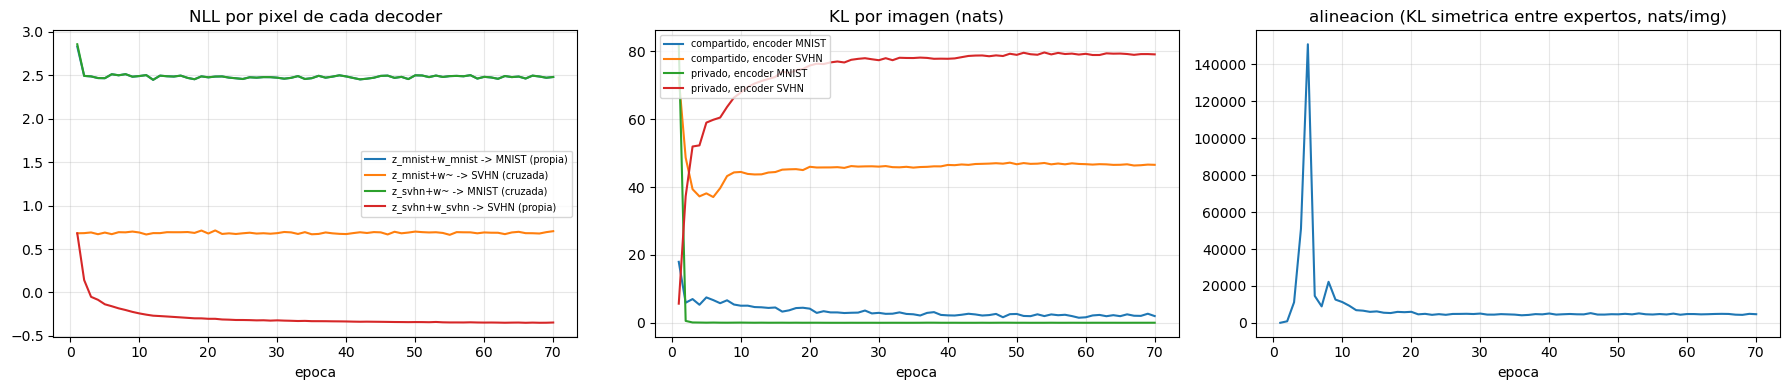

In [55]:
bpe = my_multivae.batches_per_epoch
n_ep = len(my_multivae.rec_mm_s) // bpe
ep = np.arange(1, n_ep + 1)
cur = {k: np.asarray(getattr(my_multivae, k))[:n_ep * bpe].reshape(n_ep, bpe).mean(axis=1)
       for k in ['rec_mm_s', 'rec_ms_s', 'rec_sm_s', 'rec_ss_s',
                 'kl_z1_m_s', 'kl_z1_s_s', 'kl_w_m_s', 'kl_w_s_s', 'align_s']}
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(ep, cur['rec_mm_s'], label='z_mnist+w_mnist -> MNIST (propia)')
ax[0].plot(ep, cur['rec_ms_s'], label='z_mnist+w~ -> SVHN (cruzada)')
ax[0].plot(ep, cur['rec_sm_s'], label='z_svhn+w~ -> MNIST (cruzada)')
ax[0].plot(ep, cur['rec_ss_s'], label='z_svhn+w_svhn -> SVHN (propia)')
ax[0].set_title('NLL por pixel de cada decoder'); ax[0].legend(fontsize=7)
ax[1].plot(ep, cur['kl_z1_m_s'], label='compartido, encoder MNIST')
ax[1].plot(ep, cur['kl_z1_s_s'], label='compartido, encoder SVHN')
ax[1].plot(ep, cur['kl_w_m_s'], label='privado, encoder MNIST')
ax[1].plot(ep, cur['kl_w_s_s'], label='privado, encoder SVHN')
ax[1].set_title('KL por imagen (nats)'); ax[1].legend(fontsize=7)
ax[2].plot(ep, cur['align_s'])
ax[2].set_title('alineacion (KL simetrica entre expertos, nats/img)')
for a in ax:
    a.set_xlabel('epoca'); a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

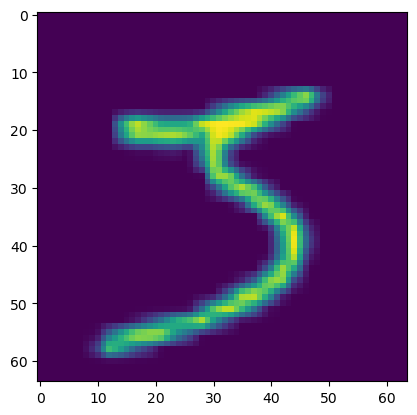

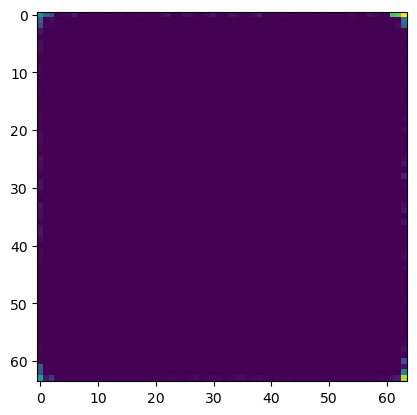

In [56]:
x_mnist, _, digit = paired_dataset[3]
i = x_mnist.unsqueeze(0)

encoded = my_multivae.encoder_m.encode_and_sample(x=i.to(my_multivae.device),flag_sample=False)

z_shared = encoded[0][0]
z_private = encoded[1][0]

    # Concatenar las representaciones
z_batch = torch.cat((z_shared, z_private), dim=1)

x_reconstructed = my_multivae.decoder_m.decode(z_batch).detach() # YOUR CODE HERE

# We plot he original image
# YOUR CODE HERE
imshow(i[0,:,:,:].to('cpu'))
# And the reconstruction
# YOUR CODE HERE
imshow(x_reconstructed[0,:,:,:].to('cpu'))


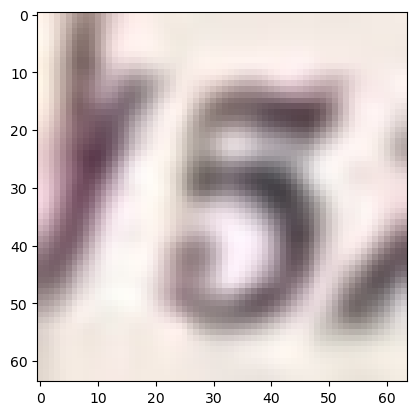

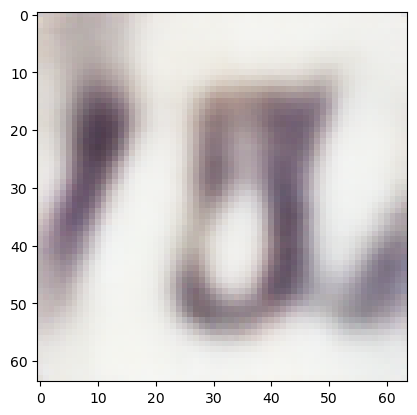

In [57]:
_, x_svhn, digit = paired_dataset[3]
i = x_svhn.unsqueeze(0)

encoded = my_multivae.encoder_s.encode_and_sample(x=i.to(my_multivae.device),flag_sample=False)

z_shared = encoded[0][0]
z_private = encoded[1][0]

    # Concatenar las representaciones
z_batch = torch.cat((z_shared, z_private), dim=1)

x_reconstructed = my_multivae.decoder_s.decode(z_batch).detach() # YOUR CODE HERE

# We plot he original image
# YOUR CODE HERE
imshow(i[0,:,:,:].to('cpu'))
# And the reconstruction
# YOUR CODE HERE
imshow(x_reconstructed[0,:,:,:].to('cpu'))


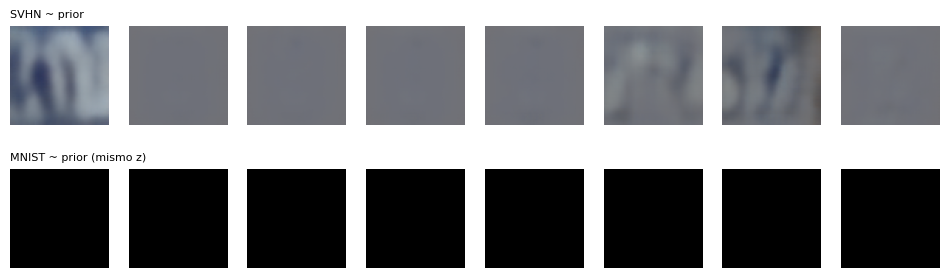

In [58]:
xs, xm = my_multivae.sample(8)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for c in range(8):
    ax[0, c].imshow((xs[c] / 2 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()); ax[0, c].axis('off')
    ax[1, c].imshow((xm[c, 0] / 2 + 0.5).clamp(0, 1).numpy(), cmap='gray', vmin=0, vmax=1); ax[1, c].axis('off')
ax[0, 0].set_title('SVHN ~ prior', loc='left', fontsize=8)
ax[1, 0].set_title('MNIST ~ prior (mismo z)', loc='left', fontsize=8)
plt.show()

In [59]:
x_m, x_s, y = next(iter(paired_loader))

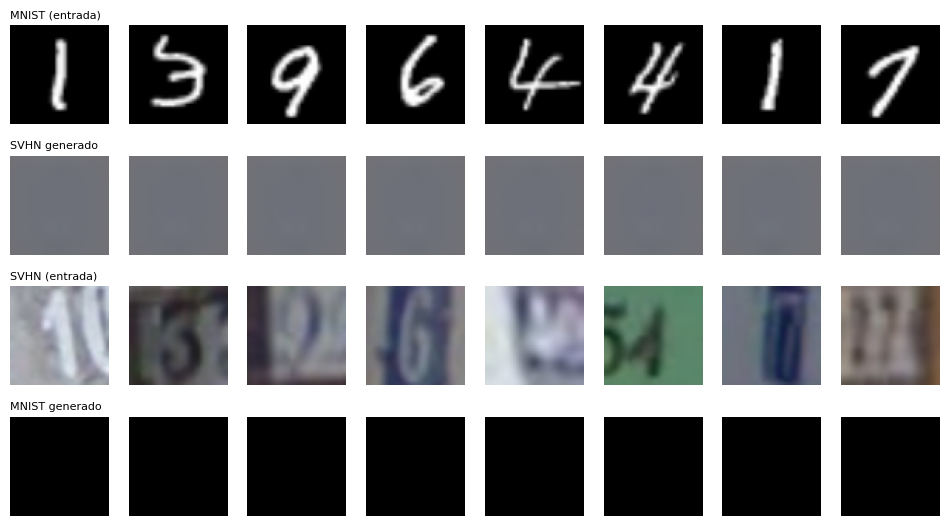

In [60]:
x_gen_s = my_multivae.cross_sample(x_mnist=x_m[:8], use_r=False)      # SVHN desde MNIST
x_gen_m = my_multivae.cross_sample(x_svhn=x_s[:8])       # MNIST desde SVHN
fig, ax = plt.subplots(4, 8, figsize=(12, 6.5))
for c in range(8):
    ax[0, c].imshow((x_m[c, 0] / 2 + 0.5).numpy(), cmap='gray', vmin=0, vmax=1)
    ax[1, c].imshow((x_gen_s[c] / 2 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy())
    ax[2, c].imshow((x_s[c] / 2 + 0.5).permute(1, 2, 0).numpy())
    ax[3, c].imshow((x_gen_m[c, 0] / 2 + 0.5).clamp(0, 1).numpy(), cmap='gray', vmin=0, vmax=1)
    for r in range(4):
        ax[r, c].axis('off')
for r, t in enumerate(['MNIST (entrada)', 'SVHN generado', 'SVHN (entrada)', 'MNIST generado']):
    ax[r, 0].set_title(t, loc='left', fontsize=8)
plt.show()

In [34]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from sklearn.manifold import TSNE

def rescale(img):
    img = img / 2 + 0.5     # unnormalize to plot
    npimg = img.detach().cpu().clamp(0, 1).numpy()
    if npimg.shape[0] == 1:
        npimg = np.repeat(npimg, 3, axis=0)
    return np.transpose(npimg, (1, 2, 0))
 
 
def plot_latent_space_with_images(images, latent, xmin=None, xmax=None, ymin=None, ymax=None, zoom=0.4, title="Latent space Z with Images"):
    f, ax = plt.subplots(1, 1, figsize=(9, 9))
    ax.clear()
    for i in range(len(images)):
        im = OffsetImage(rescale(images[i, :, :, :]), zoom=zoom)
        ab = AnnotationBbox(im, latent[i, :], frameon=False)
        ax.add_artist(ab)
    mx = 0.1 * (latent[:, 0].max() - latent[:, 0].min())
    my = 0.1 * (latent[:, 1].max() - latent[:, 1].min())
    ax.set_xlim(latent[:, 0].min() - mx if xmin is None else xmin, latent[:, 0].max() + mx if xmax is None else xmax)
    ax.set_ylim(latent[:, 1].min() - my if ymin is None else ymin, latent[:, 1].max() + my if ymax is None else ymax)
    ax.set_title(title, fontsize=12)
    plt.tight_layout()
    plt.show()


In [35]:
# 1. Obtener 100 imagenes SVHN
x_svhn = torch.stack([
    paired_dataset[j][1] for j in range(100)
]).to(my_multivae.device)

# 2. Obtener representaciones latentes desempaquetando la tupla doble: (shared), (private)
with torch.no_grad():
    (mu_shared, _, _), (mu_private, _, _) = my_multivae.encoder_s.encode_and_sample(
        x=x_svhn,
        flag_sample=False
    )

# Seleccionamos el espacio compartido z (o torch.cat([mu_shared, mu_private], dim=1) para ver ambos)
z_batch = mu_shared
print("Dimensiones z_batch SVHN:", z_batch.shape)

# 3. Reducir a 2 dimensiones con t-SNE
latent_tsne_svhn = TSNE(
    n_components=2,
    random_state=42
).fit_transform(z_batch.detach().cpu().numpy())


Dimensiones z_batch SVHN: torch.Size([100, 16])


c:\Users\sampe\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\sampe\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\sampe\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sampe\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

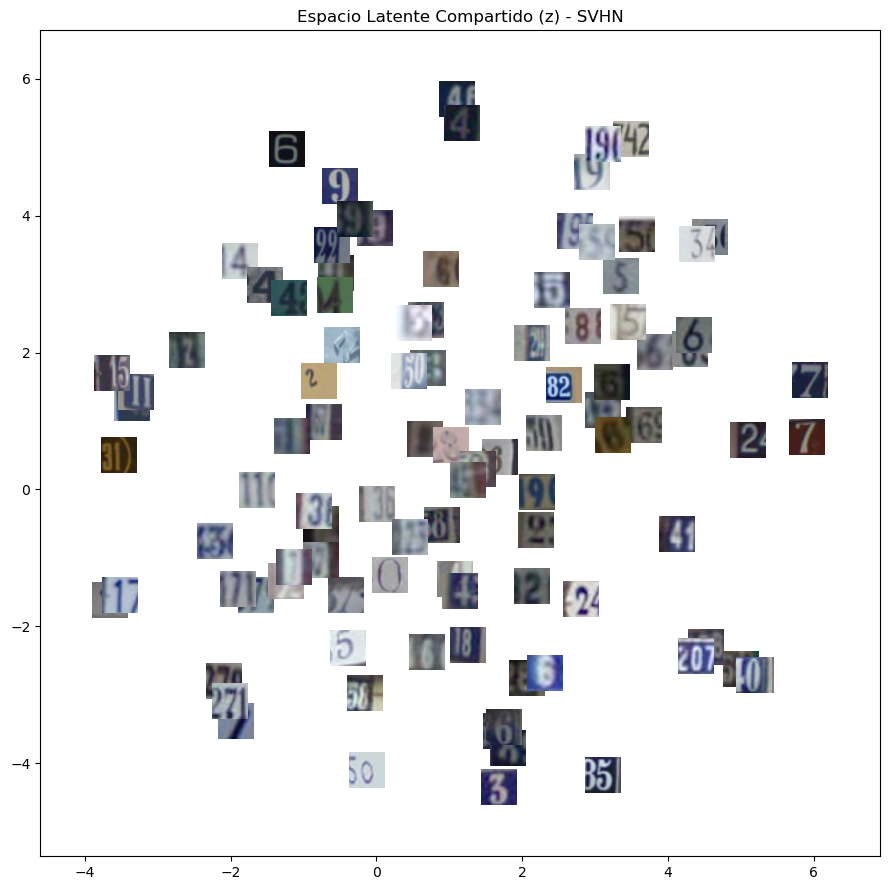

In [36]:
plot_latent_space_with_images(x_svhn.cpu(), latent_tsne_svhn, zoom=0.4, title="Espacio Latente Compartido (z) - SVHN")


In [37]:
# 1. Obtener 100 imagenes MNIST
x_mnist = torch.stack([
    paired_dataset[j][0] for j in range(100)
]).to(my_multivae.device)

# 2. Obtener representaciones latentes desempaquetando la tupla doble: (shared), (private)
with torch.no_grad():
    (mu_shared, _, _), (mu_private, _, _) = my_multivae.encoder_m.encode_and_sample(
        x=x_mnist,
        flag_sample=False
    )

# Seleccionamos el espacio compartido z
z_batch = mu_shared
print("Dimensiones z_batch MNIST:", z_batch.shape)

# 3. Reducir a 2 dimensiones con t-SNE
latent_tsne_mnist = TSNE(
    n_components=2,
    random_state=42
).fit_transform(z_batch.detach().cpu().numpy())


Dimensiones z_batch MNIST: torch.Size([100, 16])


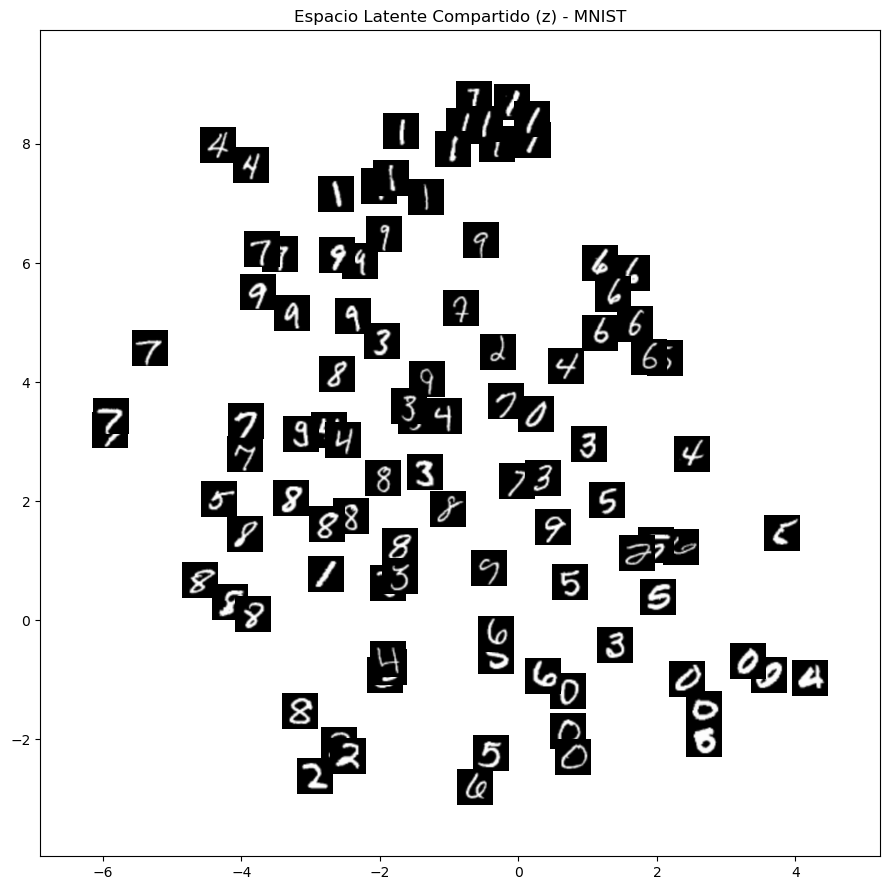

In [38]:
plot_latent_space_with_images(x_mnist.cpu(), latent_tsne_mnist, zoom=0.4, title="Espacio Latente Compartido (z) - MNIST")


In [39]:
# --- PROYECCION CONJUNTA (SVHN + MNIST) EN EL ESPACIO COMPARTIDO (z) ---
# Permite visualizar si los digitos de ambos dominios se agrupan en las mismas regiones semanticas
images_both = torch.cat([x_svhn.cpu(), x_mnist.cpu()], dim=0)
with torch.no_grad():
    (z_s, _, _), _ = my_multivae.encoder_s.encode_and_sample(x=x_svhn, flag_sample=False)
    (z_m, _, _), _ = my_multivae.encoder_m.encode_and_sample(x=x_mnist, flag_sample=False)
z_both = torch.cat([z_s, z_m], dim=0)

latent_tsne_both = TSNE(n_components=2, random_state=42).fit_transform(z_both.detach().cpu().numpy())
plot_latent_space_with_images(images_both, latent_tsne_both, zoom=0.35, title="Espacio Compartido (z) - SVHN + MNIST Conjuntos")


RuntimeError: Sizes of tensors must match except in dimension 0. Expected size 3 but got size 1 for tensor number 1 in the list.